# Module 7 Lab 1: Train, Test, Tell the Truth

### First Predictive Models with scikit-learn

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

This lab trains three models: a line that predicts tips from the bill, and two classifiers that guess an iris flower's species. Every model gets graded on data it never saw during training, and at the end we check what happens when a tree is allowed to memorize.

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree

import sklearn
print('scikit-learn version:', sklearn.__version__)

scikit-learn version: 1.9.1


## Step 1: Load tips.csv and frame the problem

The feature (X) is `total_bill` and the target (y) is `tip`.

In [2]:
tips = pd.read_csv('tips.csv')
print(tips.shape)
tips.head()

(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
X = tips[['total_bill']]   # double brackets so X stays a DataFrame (2D)
y = tips['tip']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print('training rows:', len(X_train))
print('test rows:    ', len(X_test))

training rows: 170
test rows:     74


## Step 2: Why hold out 30%?

We held out 30% of the rows so we could test the regression on bills it never saw during training. If we graded it on the same rows it learned from, it could look good just because it had already seen them, which doesn't tell us how it handles new bills.

## Step 3: Fit the regression and read the slope

In [4]:
reg = LinearRegression()
reg.fit(X_train, y_train)

slope = reg.coef_[0]
intercept = reg.intercept_
print(f'slope:     {slope:.4f}')
print(f'intercept: {intercept:.4f}')
print(f'R^2 on the TEST set: {reg.score(X_test, y_test):.3f}')

slope:     0.1089
intercept: 0.8770
R^2 on the TEST set: 0.429


**Slope sentence:** each extra dollar of bill adds about **\$0.11** of tip (about 11 cents per dollar).

The intercept (about \$0.88) is what the line predicts for a \$0 bill, which isn't a real situation, so we don't read much into it.

## Step 4: Draw the fitted line

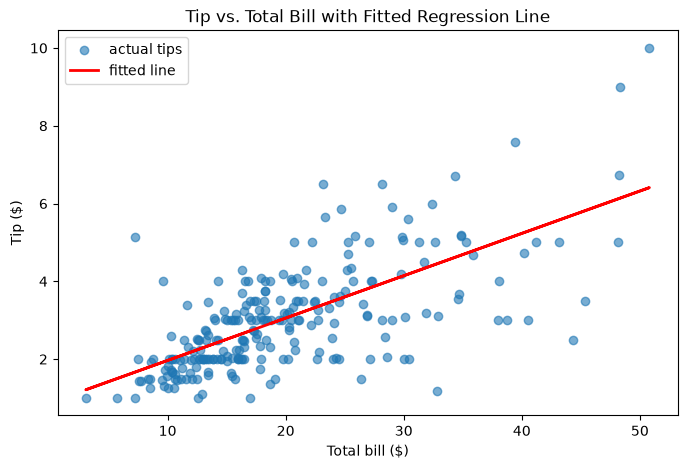

In [5]:
line_y = reg.predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(tips['total_bill'], tips['tip'], alpha=0.6, label='actual tips')
plt.plot(tips['total_bill'], line_y, color='red', linewidth=2, label='fitted line')
plt.title('Tip vs. Total Bill with Fitted Regression Line')
plt.xlabel('Total bill ($)')
plt.ylabel('Tip ($)')
plt.legend()
plt.show()

### What the line is saying

The fitted model is:

$$\widehat{\text{tip}} = 0.88 + 0.109 \times \text{total bill}$$

So for a \$20 bill the model predicts $0.88 + 0.109 \times 20 \approx \$3.06$, and for a \$40 bill about \$5.24. Each extra dollar of bill adds roughly 11 cents of tip.

**Why it's roughly good:** the dots clearly trend upward, and an 11% slope is close to how people actually tip. On the 74 test bills the model gets an $R^2$ of about 0.43, so the bill alone explains about 43% of why tips differ.

**Why it's too simple:** the other 57% comes from things the line can't see. It only uses one feature, so it ignores things like party size, day, and time. It also assumes every table tips the same way, but in the plot the dots spread out more as bills get bigger, so the line misses big bills by more. It's useful for the general trend, not for predicting any one table's exact tip.

**Checkpoint:** the printed slope (about 0.109) matches the slope sentence, and X is `total_bill`, y is `tip`, so nothing is reversed.

## Step 5: Load iris and split it

In [6]:
iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target
species = iris.target_names   # 0 = setosa, 1 = versicolor, 2 = virginica

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42)

print('total flowers:', len(X_iris))
print('training:     ', len(Xi_train))
print('test:         ', len(Xi_test))
X_iris.head()

total flowers: 150
training:      105
test:          45


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## Step 6: Fit and score kNN (test set only)

In [7]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(Xi_train, yi_train)

print(f'kNN accuracy on TEST: {knn.score(Xi_test, yi_test):.3f}')

kNN accuracy on TEST: 1.000


## Step 7: Fit, score, and read a shallow tree

In [8]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xi_train, yi_train)

print(f'Shallow tree accuracy on TEST: {tree.score(Xi_test, yi_test):.3f}')

Shallow tree accuracy on TEST: 1.000


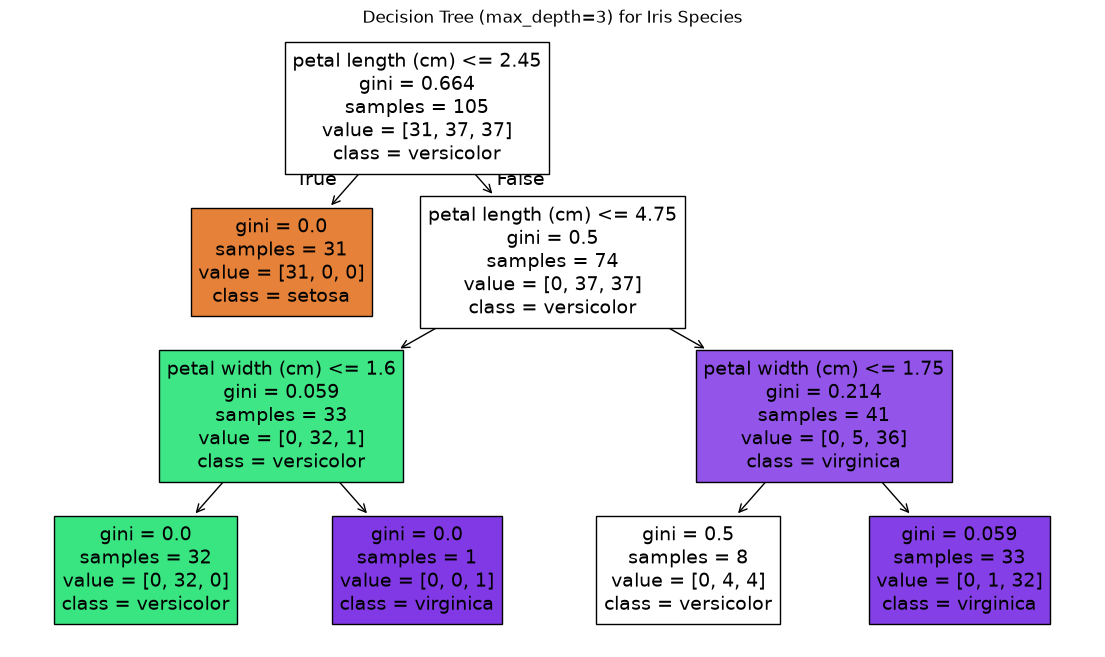

In [9]:
plt.figure(figsize=(14, 8))
plot_tree(tree, feature_names=list(X_iris.columns),
          class_names=list(species), filled=True)
plt.title('Decision Tree (max_depth=3) for Iris Species')
plt.show()

The tree's first question is whether petal width is 0.8 cm or less. If it is, the flower is classified as setosa; if not, it moves on to the next split to decide between the other two species.

## Step 8: The overfitting probe

In [10]:
deep_tree = DecisionTreeClassifier(random_state=42)   # no max_depth = can grow until it memorizes
deep_tree.fit(Xi_train, yi_train)

probe = pd.DataFrame({
    'model': ['shallow tree (max_depth=3)', 'unlimited tree'],
    'train accuracy': [tree.score(Xi_train, yi_train), deep_tree.score(Xi_train, yi_train)],
    'test accuracy':  [tree.score(Xi_test, yi_test),  deep_tree.score(Xi_test, yi_test)],
}).round(3)

print('unlimited tree depth:', deep_tree.get_depth())
probe

unlimited tree depth: 6


,model,train accuracy,test accuracy
0,shallow tree (max_depth=3),0.952,1.0
1,unlimited tree,1.000,1.0


The unlimited tree hits a perfect 1.000 on the training data, but it also scores 1.000 on the test set, exactly like the shallow tree. So all that extra complexity didn't buy any improvement on new flowers.

## Step 9: Predict one new flower

In [11]:
# my made-up flower: sepal length, sepal width, petal length, petal width (cm)
new_flower = pd.DataFrame([[6.1, 2.9, 4.6, 1.4]], columns=X_iris.columns)

pred = tree.predict(new_flower)[0]
print('predicted species:', species[pred])

predicted species: versicolor


## Step 10: Model report

The model predicts an iris flower's species from four measurements: sepal length, sepal width, petal length, and petal width. For a made-up flower measuring 6.1, 2.9, 4.6, and 1.4 cm, the tree predicts **versicolor**. We'd go with the shallow tree: it tied the unlimited tree at a perfect 1.000 on the 45 test flowers, and it's much easier to read and explain.

The model could struggle with a flower from a species it was never trained on, or with measurements that look different from the training data. And since the test set is small, a perfect score doesn't guarantee it will be perfect on new flowers.

If this were a model about people, groups that are underrepresented in the training data could get less accurate predictions. In that case, we'd check how well the model does for each group and work on getting more balanced data.

## Appendix: AI Use

- **What Claude did:** set up the notebook structure and the scikit-learn code for each step (splits, fitting, scoring, the plots, and the overfitting table).
- **Key prompts (paraphrased):**
  - How can I split the data and use scikit-learn to train and score decision-tree and kNN models?
  - How can I plot the decision tree and compare models with different settings to check for overfitting?
  - How should I make a table to compare the models' training and test performance?
  - Tips formula breakdown
  - Refine my wording so it's not redundant and reads more professionally.